# Lab01 — Sprint 1

## Random Variable 01: quality

**Роль:** Инфохимик года № 1 — статистик-эмпирик  
**Датасет:** Wine Quality (Vinho Verde, Portugal), Cortez et al. (2009)  
**Целевая переменная:** quality — сенсорная оценка качества вина

### Description (природа события)

quality — итоговая оценка вина, выставленная группой дегустаторов (минимум 3 человека).
Каждую пробу оценивали вслепую, итоговый балл — медиана их оценок.

**Почему это случайная величина:**
Оценка зависит от человеческого восприятия — вкус относится к наименее изученным чувствам
(Cortez et al., 2009). Связь между физико-химическими показателями и сенсорной оценкой
сложна и не описывается детерминированной формулой.

Мы моделируем Q как случайную величину: оценку случайно выбранной пробы
из рассматриваемой совокупности вин. В самом датасете оценка каждой
конкретной пробы зафиксирована, случайность относится к модели выбора.

In [ ]:
pip install mamba

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.0/258.0 kB 7.7 MB/s eta 0:00:00
  Created wheel for mamba: filename=mamba-0.11.3-py3-none-any.whl size=16379 sha256=592d30b6d64fc885ed3d1019aef080157c255c06999f9c7c297943d936e5547d
  Stored in directory: /root/.cache/pip/wheels/ae/d9/97/619f1501b24449cadd27983f0f667bdde52efb1f2b83469978
  Created wheel for clint: filename=clint-0.5.1-py3-none-any.whl size=34577 sha256=0db316356b9b406888928cbc996bb745173da09ecc602638a11535b0a1f969f6
  Stored in directory: /root/.cache/pip/wheels/81/3b/0a/7cb5487a439d8464cbeed85b96ccdd5a2b8ed216ddfb00c0db
  Created wheel for args: filename=args-0.1.0-py3-none-any.whl size=3361 sha256=850f47eeee0f761a08ed6e99ee4cfab90f3a162ced694b18bd989aa1db6a8543
  Stored in directory: /root/.cache/pip/wheels/ae/52/c7/44a72935044db819a337f00a3a2de90d42c93e1afb3c7ec4a2
Successfully built mamba clint arg

In [ ]:
pip install pandas numpy matplotlib scipy

In [6]:

# 1. Импорт библиотек и настройки
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# 2. Проверка наличия файлов
required_files = [
    "winequality-red.csv",
    "winequality-white.csv"
]

missing_files = [
    filename for filename in required_files
    if not os.path.isfile(filename)
]

if missing_files:
    raise FileNotFoundError(
        "Не найдены файлы: "
        + ", ".join(missing_files)
        + ". Проверь рабочую папку ноутбука."
    )

# 3. Загрузка данных
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

red["color"] = "red"
white["color"] = "white"

df = pd.concat([red, white], ignore_index=True)

# 4. Первичная проверка
print("Красное вино:", red.shape)
print("Белое вино:", white.shape)
print("Общий датасет:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Полные дубликаты:", df.duplicated().sum())

display(df.head())


Красное вино: (1599, 13)
Белое вино: (4898, 13)
Общий датасет: (6497, 13)
Пропуски: 0
Полные дубликаты: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [7]:
df.info() #проверка даннх на вменяемость

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [8]:
print("Пропуски всего:", df.isna().sum().sum())

print("Дубликаты:     ", df.duplicated().sum())
print("Размер:        ", df.shape)

Пропуски всего: 0
Дубликаты:      1177
Размер:         (6497, 13)


### EDA & Distribution

Основные статистики, форма распределения, ECDF.

In [9]:
q = df["quality"]

print("Тип данных:      ", q.dtype)
print("Наблюдений:      ", q.count())
print("Пропусков:       ", q.isna().sum())
print("Уникальные оценки:", sorted(q.unique()))

q.describe()

Тип данных:       int64
Наблюдений:       6497
Пропусков:        0
Уникальные оценки: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


,quality
count,6497.000000
mean,5.818378
std,0.873255
min,3.000000
25%,5.000000
50%,6.000000
75%,6.000000
max,9.000000


In [10]:

# Получаем оценки качества без пропусков
q = df["quality"].dropna()

# Ключевые описательные статистики quality
print(f"Среднее:          {q.mean():.4f}")
print(f"Медиана:          {q.median():.4f}")
print(f"Мода:             {q.mode().tolist()}")
print(f"Дисперсия:        {q.var():.4f}")
print(f"Стд. отклонение:  {q.std():.4f}")
print(f"Асимметрия:       {stats.skew(q):.4f}")
print(f"Эксцесс:          {stats.kurtosis(q):.4f}")

# Количество наблюдений и доля каждого значения quality
quality_counts = q.value_counts().sort_index()
quality_shares = q.value_counts(normalize=True).sort_index() * 100

quality_table = pd.DataFrame({
    "Количество": quality_counts,
    "Доля, %": quality_shares
})

print(f"\nОбщее количество наблюдений: {q.count()}")
display(quality_table.round(2))


Среднее:          5.8184
Медиана:          6.0000
Мода:             [6]
Дисперсия:        0.7626
Стд. отклонение:  0.8733
Асимметрия:       0.1896
Эксцесс:          0.2312

Общее количество наблюдений: 6497


,Количество,"Доля, %"
quality,,
3,30,0.46
4,216,3.32
5,2138,32.91
6,2836,43.65
7,1079,16.61
8,193,2.97
9,5,0.08


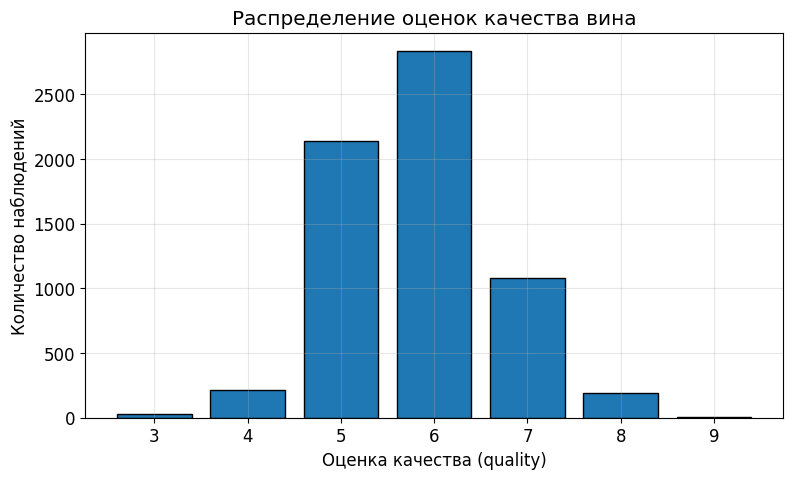

In [11]:
# гистограмма и в ней мы считаем, сколько раз встречается каждая оценка, и сортируем по возрастанию
quality_counts = q.value_counts().sort_index()

plt.figure(figsize=(9, 5))

plt.bar(
    quality_counts.index,
    quality_counts.values,
    edgecolor="black"
)

plt.title("Распределение оценок качества вина")
plt.xlabel("Оценка качества (quality)")
plt.ylabel("Количество наблюдений")
plt.xticks(quality_counts.index)
plt.grid(axis="y", alpha=0.3)
plt.show()

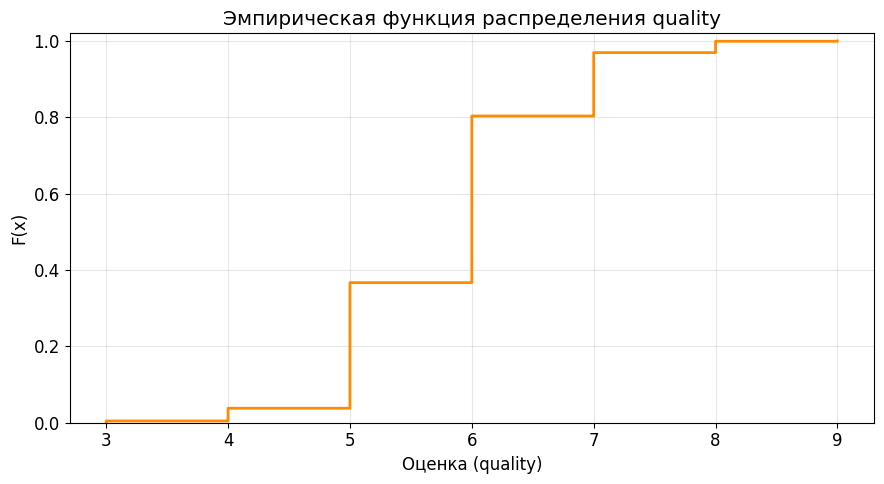

In [12]:
# Сортируем здесь всеее значения quality по возрастанию
x = np.sort(q.to_numpy())
# Для каждой точки считаем долю наблюдений, не превышающих её
# (i / N — это и есть эмпирическая функция распределения)
y = np.arange(1, len(x) + 1) / len(x)

# Ну тут строился ступенчатый график: where="post" - это знач ступенька идёт вправо
fig, ax = plt.subplots()
ax.step(x, y, where="post", color="darkorange", linewidth=2)
ax.set_title("Эмпирическая функция распределения quality")
ax.set_xlabel("Оценка (quality)")
ax.set_ylabel("F(x)")
ax.set_xticks(sorted(q.unique()))
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

### Вывод по исследовательскому анализу данных (EDA)

Переменная `quality` принимает целочисленные значения от 3 до 9 в рассматриваемом датасете. Это дискретная порядковая шкала: оценки упорядочены, но равные расстояния между баллами не обязательно соответствуют равным различиям в восприятии качества.

Основные описательные статистики и доли отдельных оценок приведены в таблицах выше. Гистограмма и эмпирическая функция распределения показывают, какие оценки встречаются чаще и как накапливается доля наблюдений.

Результат теста Д’Агостино—Пирсона приведён в следующей ячейке. Статистическое отклонение от нормального распределения не означает, что данные непригодны для анализа: необходимо учитывать дискретность шкалы, большой объём выборки и предположения конкретных статистических методов.

In [13]:
# Проверка нормальности распределения quality
# Тест Д'Агостино—Пирсона проверяет нулевую гипотезу о нормальности.

q = df["quality"].dropna()
alpha = 0.05

normality_result = stats.normaltest(q)

print(f"Количество наблюдений: {len(q)}")
print(f"Статистика теста: {normality_result.statistic:.4f}")
print(f"p-value: {normality_result.pvalue:.6g}")
print(f"Уровень значимости alpha: {alpha}")

if normality_result.pvalue < alpha:
    print(
        "Решение: отвергаем гипотезу о нормальности "
        "на уровне значимости 0.05."
    )
else:
    print(
        "Решение: нет достаточных оснований отвергнуть "
        "гипотезу о нормальности на уровне значимости 0.05."
    )

print(
    "Примечание: quality — дискретная порядковая переменная. "
    "Результат теста следует интерпретировать с учётом этого свойства."
)

Количество наблюдений: 6497
Статистика теста: 50.3590
p-value: 1.16061e-11
Уровень значимости alpha: 0.05
Решение: отвергаем гипотезу о нормальности на уровне значимости 0.05.
Примечание: quality — дискретная порядковая переменная. Результат теста следует интерпретировать с учётом этого свойства.


In [14]:


# Моделирование выборок с возвращением и без возвращения

SEED = 42
N_REPEATS = 1000
SAMPLE_SIZES = [10, 30, 50, 100, 300, 500, 1000]

population = df["quality"].dropna().to_numpy(dtype=float)
N = len(population)
mu = population.mean()
sigma2 = population.var(ddof=0)

rng = np.random.default_rng(SEED)
results = []

for n in SAMPLE_SIZES:
    if n > N:
        continue

    means_wr = np.empty(N_REPEATS)
    means_wor = np.empty(N_REPEATS)

    for i in range(N_REPEATS):
        means_wr[i] = rng.choice(
            population, size=n, replace=True
        ).mean()

        means_wor[i] = rng.choice(
            population, size=n, replace=False
        ).mean()

    # Теоретическая SE среднего
    se_wr = np.sqrt(sigma2 / n)
    se_wor = np.sqrt(
        sigma2 / n * (N - n) / (N - 1)
    )

    # RMSE отдельной оценки среднего относительно mu
    rmse_wr = np.sqrt(np.mean((means_wr - mu) ** 2))
    rmse_wor = np.sqrt(np.mean((means_wor - mu) ** 2))

    results.append({
        "n": n,
        "Среднее WR": means_wr.mean(),
        "Среднее WOR": means_wor.mean(),
        "Смещение WR": means_wr.mean() - mu,
        "Смещение WOR": means_wor.mean() - mu,
        "SD средних WR": means_wr.std(ddof=1),
        "SD средних WOR": means_wor.std(ddof=1),
        "RMSE WR": rmse_wr,
        "RMSE WOR": rmse_wor,
        "Теоретическая SE WR": se_wr,
        "Теоретическая SE WOR": se_wor
    })

sampling_results = pd.DataFrame(results)

print(f"Размер полной совокупности: {N}")
print(f"Среднее полной совокупности: {mu:.6f}")
print(f"Число повторений для каждого n: {N_REPEATS}")

display(sampling_results.round(5))


Размер полной совокупности: 6497
Среднее полной совокупности: 5.818378
Число повторений для каждого n: 1000


,n,Среднее WR,Среднее WOR,Смещение WR,Смещение WOR,SD средних WR,SD средних WOR,RMSE WR,RMSE WOR,Теоретическая SE WR,Теоретическая SE WOR
0,10,5.82320,5.80870,0.00482,-0.00968,0.27235,0.28996,0.27226,0.28998,0.27613,0.27593
1,30,5.83157,5.80930,0.01319,-0.00908,0.16180,0.15578,0.16226,0.15597,0.15942,0.15907
2,50,5.81244,5.81092,-0.00594,-0.00746,0.12424,0.12299,0.12432,0.12315,0.12349,0.12302
3,100,5.82137,5.81947,0.00299,0.00109,0.08866,0.08528,0.08866,0.08524,0.08732,0.08665
4,300,5.82009,5.81737,0.00171,-0.00101,0.04953,0.05115,0.04953,0.05113,0.05041,0.04924
5,500,5.81700,5.81855,-0.00138,0.00017,0.03823,0.03778,0.03824,0.03776,0.03905,0.03752
6,1000,5.81940,5.81919,0.00103,0.00081,0.02756,0.02553,0.02756,0.02553,0.02761,0.02540


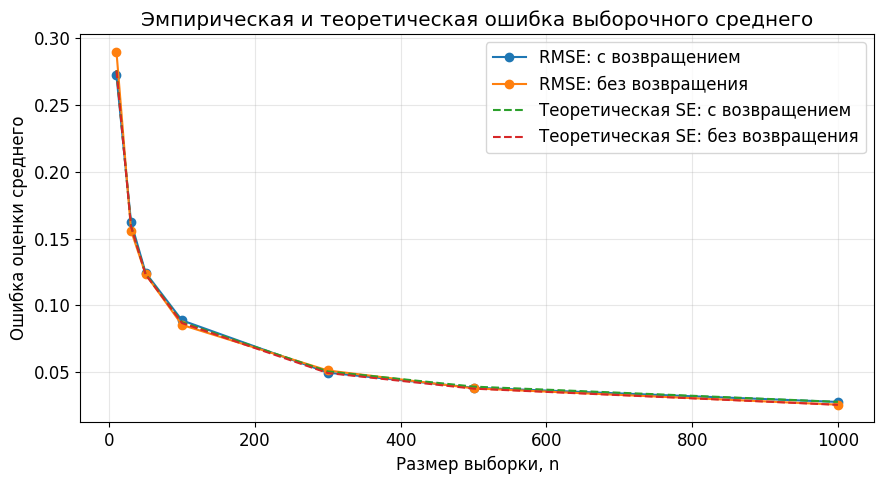

In [15]:


# Сравнение эмпирической RMSE с теоретической стандартной ошибкой

plt.figure(figsize=(9, 5))

plt.plot(
    sampling_results["n"],
    sampling_results["RMSE WR"],
    "o-",
    label="RMSE: с возвращением"
)

plt.plot(
    sampling_results["n"],
    sampling_results["RMSE WOR"],
    "o-",
    label="RMSE: без возвращения"
)

plt.plot(
    sampling_results["n"],
    sampling_results["Теоретическая SE WR"],
    "--",
    label="Теоретическая SE: с возвращением"
)

plt.plot(
    sampling_results["n"],
    sampling_results["Теоретическая SE WOR"],
    "--",
    label="Теоретическая SE: без возвращения"
)

plt.xlabel("Размер выборки, n")
plt.ylabel("Ошибка оценки среднего")
plt.title("Эмпирическая и теоретическая ошибка выборочного среднего")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

# Сравнение полной совокупности и двух случайных выборок

comparison_rng = np.random.default_rng(2026)

population = df["quality"].dropna().to_numpy(dtype=float)
n = 30

sample_wr = comparison_rng.choice(
    population, size=n, replace=True
)
sample_wor = comparison_rng.choice(
    population, size=n, replace=False
)

quality_values = sorted(np.unique(population))

def calculate_metrics(data, name, is_population=False):
    data = np.asarray(data, dtype=float)

    result = {
        "Данные": name,
        "Объём": len(data),
        "Среднее": np.mean(data),
        "Медиана": np.median(data),
        "Дисперсия": np.var(
            data, ddof=0 if is_population else 1
        )
    }

    for value in quality_values:
        result[f"Доля оценки {int(value)}, %"] = (
            np.mean(data == value) * 100
        )

    return result

comparison_table = pd.DataFrame([
    calculate_metrics(
        population, "Полный датасет", is_population=True
    ),
    calculate_metrics(
        sample_wr, "Выборка с возвращением"
    ),
    calculate_metrics(
        sample_wor, "Выборка без возвращения"
    )
])

display(comparison_table.round(3))


,Данные,Объём,Среднее,Медиана,Дисперсия,"Доля оценки 3, %","Доля оценки 4, %","Доля оценки 5, %","Доля оценки 6, %","Доля оценки 7, %","Доля оценки 8, %","Доля оценки 9, %"
0,Полный датасет,6497,5.818,6.0,0.762,0.462,3.325,32.907,43.651,16.608,2.971,0.077
1,Выборка с возвращением,30,5.900,6.0,0.783,0.000,3.333,30.000,43.333,20.000,3.333,0.000
2,Выборка без возвращения,30,5.933,6.0,0.685,0.000,0.000,36.667,33.333,30.000,0.000,0.000


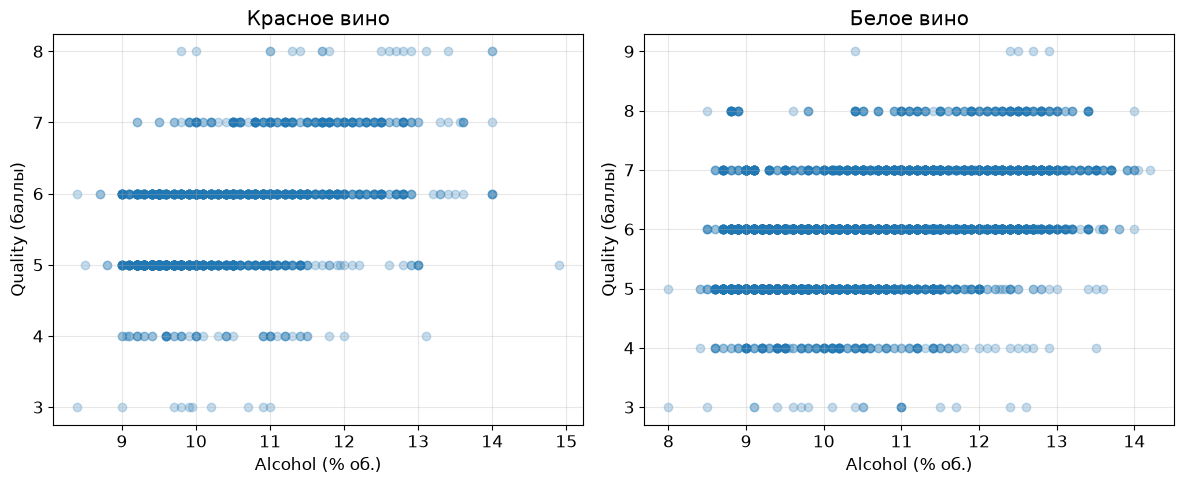

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, color in zip(axes, ["red", "white"]):
    subset = df.loc[df["color"] == color]

    ax.scatter(
        subset["alcohol"],
        subset["quality"],
        alpha=0.25
    )

    ax.set_title(
        "Красное вино" if color == "red"
        else "Белое вино"
    )
    ax.set_xlabel("Alcohol (% об.)")
    ax.set_ylabel("Quality (баллы)")

plt.tight_layout()
plt.show()

In [17]:

from scipy import stats
import pandas as pd

correlation_results = []

for color in ["red", "white"]:
    subset = df.loc[
        df["color"] == color,
        ["alcohol", "quality"]
    ].dropna()

    # Корреляция Пирсона: линейная связь числовых переменных
    pearson_r, pearson_p = stats.pearsonr(
        subset["alcohol"],
        subset["quality"]
    )

    # Корреляция Спирмена: связь между рангами
    spearman_r, spearman_p = stats.spearmanr(
        subset["alcohol"],
        subset["quality"]
    )

    correlation_results.append({
        "Тип вина": color,
        "Объём": len(subset),
        "Пирсон r": pearson_r,
        "p-value Пирсона": pearson_p,
        "Спирмен ρ": spearman_r,
        "p-value Спирмена": spearman_p
    })

correlation_table = pd.DataFrame(correlation_results)

display(correlation_table.round(5))


,Тип вина,Объём,Пирсон r,p-value Пирсона,Спирмен ρ,p-value Спирмена
0,red,1599,0.47617,0.0,0.47853,0.0
1,white,4898,0.43557,0.0,0.44037,0.0


### Интерпретация переменной quality

Переменная `quality` представляет собой оценку качества вина по шкале от 0 до 10. В исследуемом датасете наблюдаемые значения находятся в диапазоне от 3 до 9. Эта переменная имеет порядковый характер: значения отражают порядок оценок, но расстояния между соседними оценками не обязательно являются одинаковыми с точки зрения восприятия качества.

В дальнейшем среднее и дисперсия используются как описательные характеристики при условном допущении, что числовые различия между соседними оценками можно приближённо трактовать как сопоставимые. Это допущение упрощает статистическое сравнение, но не превращает порядковую шкалу в интервальную и должно учитываться при интерпретации результатов.

Стандартизация переменной, например с помощью z-преобразования, меняет её масштаб, но не устраняет дискретность и не делает распределение нормальным. Поэтому нормальность следует проверять отдельно, а результаты статистических тестов интерпретировать с учётом свойств данных.

In [18]:
# Разделение наблюдений по цвету вина

kr = df.loc[df["color"] == "red", "quality"].dropna()
bl = df.loc[df["color"] == "white", "quality"].dropna()

print("Красное вино:")
print(kr.describe().round(3))

print("\nБелое вино:")
print(bl.describe().round(3))

print(f"\nОбъём красного вина: {len(kr)}")
print(f"Объём белого вина: {len(bl)}")

Красное вино:
count    1599.000
mean        5.636
std         0.808
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         8.000
Name: quality, dtype: float64

Белое вино:
count    4898.000
mean        5.878
std         0.886
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         9.000
Name: quality, dtype: float64

Объём красного вина: 1599
Объём белого вина: 4898


### Проверка гипотезы

H0: μ_red = μ_white — средние оценки одинаковы.
H1: μ_red ≠ μ_white — средние различаются.
α = 0.05.
Используем Welch t-test — он не требует равенства дисперсий.

In [19]:
# Сравнение средних оценок красного и белого вина
# H0: средние равны; H1: средние различаются.
# Используется двусторонний t-критерий Уэлча.

alpha = 0.05

t_res = stats.ttest_ind(kr, bl, equal_var=False)

mean_red = kr.mean()
mean_white = bl.mean()
diff = mean_red - mean_white

var_red = kr.var(ddof=1)
var_white = bl.var(ddof=1)

term_red = var_red / len(kr)
term_white = var_white / len(bl)

se = np.sqrt(term_red + term_white)

# Степени свободы по формуле Welch–Satterthwaite
df_w = (term_red + term_white) ** 2 / (
    term_red ** 2 / (len(kr) - 1)
    + term_white ** 2 / (len(bl) - 1)
)

t_crit = stats.t.ppf(1 - alpha / 2, df_w)
ci_low = diff - t_crit * se
ci_high = diff + t_crit * se

print(f"Объём красного вина: {len(kr)}")
print(f"Объём белого вина: {len(bl)}")
print(f"Среднее красного вина: {mean_red:.4f}")
print(f"Среднее белого вина: {mean_white:.4f}")
print(f"Разность средних (red - white): {diff:.4f}")
print(f"t-статистика: {t_res.statistic:.4f}")
print(f"Степени свободы: {df_w:.2f}")
print(f"p-value: {t_res.pvalue:.6g}")
print(f"95%-й ДИ разности: ({ci_low:.4f}, {ci_high:.4f})")

if t_res.pvalue < alpha:
    print("Решение: отвергаем H0 при alpha = 0.05.")
else:
    print("Решение: нет оснований отвергнуть H0 при alpha = 0.05.")

Объём красного вина: 1599
Объём белого вина: 4898
Среднее красного вина: 5.6360
Среднее белого вина: 5.8779
Разность средних (red - white): -0.2419
t-статистика: -10.1494
Степени свободы: 2950.75
p-value: 8.16835e-24
95%-й ДИ разности: (-0.2886, -0.1952)
Решение: отвергаем H0 при alpha = 0.05.


In [23]:
# Размер эффекта Cohen's d
# Знак соответствует разности средних (red - white).

n1, n2 = len(kr), len(bl)

pooled_variance = (
    (n1 - 1) * kr.var(ddof=1)
    + (n2 - 1) * bl.var(ddof=1)
) / (n1 + n2 - 2)

pooled_sd = np.sqrt(pooled_variance)
cohens_d = (kr.mean() - bl.mean()) / pooled_sd
abs_d = abs(cohens_d)

if abs_d < 0.2:
    effect_label = "пренебрежимо малый"
elif abs_d < 0.5:
    effect_label = "малый"
elif abs_d < 0.8:
    effect_label = "средний"
else:
    effect_label = "большой"

print(f"Объединённое стандартное отклонение: {pooled_sd:.4f}")
print(f"Cohen's d: {cohens_d:.4f}")
print(f"|Cohen's d|: {abs_d:.4f}")
print(f"Ориентировочная оценка размера эффекта: {effect_label}")

Объединённое стандартное отклонение: 0.8671
Cohen's d: -0.2790
|Cohen's d|: 0.2790
Ориентировочная оценка размера эффекта: малый


In [25]:
# 1. Подготовка данных без полных дубликатов
df_deduplicated = df.drop_duplicates()

kr_dedup = df_deduplicated.loc[df_deduplicated["color"] == "red", "quality"].dropna()
bl_dedup = df_deduplicated.loc[df_deduplicated["color"] == "white", "quality"].dropna()

# 2. Welch t-test для обеих ситуаций
t_res_original = stats.ttest_ind(kr, bl, equal_var=False)
t_res_dedup = stats.ttest_ind(kr_dedup, bl_dedup, equal_var=False)

# 3. Создание пропущенной таблицы duplicate_comparison
duplicate_comparison = pd.DataFrame([
    {
        "Разность средних": kr.mean() - bl.mean(),
        "p-value": t_res_original.pvalue
    },
    {
        "Разность средних": kr_dedup.mean() - bl_dedup.mean(),
        "p-value": t_res_dedup.pvalue
    }
], index=["С дубликатами", "Без дубликатов"])

# 4. Интерпретация анализа чувствительности к дубликатам
original = duplicate_comparison.iloc[0]
deduplicated = duplicate_comparison.iloc[1]

print("Сравнение Welch до и после удаления полных дубликатов")
print(
    f"Разность средних с дубликатами: "
    f"{original['Разность средних']:.4f}"
)
print(
    f"Разность средних без дубликатов: "
    f"{deduplicated['Разность средних']:.4f}"
)
print(
    f"p-value с дубликатами: {original['p-value']:.6g}"
)
print(
    f"p-value без дубликатов: {deduplicated['p-value']:.6g}"
)

same_direction = (
    np.sign(original["Разность средних"])
    == np.sign(deduplicated["Разность средних"])
)

both_significant = (
    original["p-value"] < 0.05
    and deduplicated["p-value"] < 0.05
)

if same_direction and both_significant:
    print(
        "Вывод устойчив к удалению полных дубликатов "
        "по направлению различия и статистической значимости."
    )
else:
    print(
        "После удаления дубликатов результат изменился "
        "по направлению различия или статистической значимости. "
        "Интерпретируйте чувствительность отдельно."
    )

print(
    "Важно: дубликаты могут быть повторными измерениями "
    "или повторяющимися строками; их наличие само по себе "
    "не доказывает ошибку данных."
)

Сравнение Welch до и после удаления полных дубликатов
Разность средних с дубликатами: -0.2419
Разность средних без дубликатов: -0.2316
p-value с дубликатами: 8.16835e-24
p-value без дубликатов: 3.60473e-18
Вывод устойчив к удалению полных дубликатов по направлению различия и статистической значимости.
Важно: дубликаты могут быть повторными измерениями или повторяющимися строками; их наличие само по себе не доказывает ошибку данных.


### Вывод по гипотезе о различии качества красного и белого вина

Проверялись гипотезы:

- \(H_0: \mu_{\text{red}} = \mu_{\text{white}}\) — средние оценки равны.
- \(H_1: \mu_{\text{red}} \ne \mu_{\text{white}}\) — средние оценки различаются.

Для сравнения использован двусторонний t-критерий Уэлча, который не предполагает равенства дисперсий двух групп. Решение принимается при уровне значимости \(\alpha = 0.05\).

Разность средних рассчитана как \(\bar{x}_{\text{red}} - \bar{x}_{\text{white}}\). Отрицательная разность означает, что средняя оценка красного вина ниже средней оценки белого. Доверительный интервал позволяет оценить неопределённость этой разности, а Cohen's \(d\) — величину различия в единицах объединённого стандартного отклонения.

Фактические значения статистики, p-value, доверительного интервала и размера эффекта приведены в двух предыдущих ячейках.

**Ограничение:** статистически значимое различие не доказывает, что его причиной является цвет вина. На оценку также могут влиять сорт винограда, технология производства, регион и другие характеристики.

In [26]:


# Корреляция alcohol и quality для объединённого датасета

correlation_data = df[["alcohol", "quality"]].dropna()

spearman_result = stats.spearmanr(
    correlation_data["alcohol"],
    correlation_data["quality"]
)

pearson_result = stats.pearsonr(
    correlation_data["alcohol"],
    correlation_data["quality"]
)

print(f"Количество наблюдений: {len(correlation_data)}")
print(f"Спирмен rho: {spearman_result.statistic:.4f}")
print(f"p-value Спирмена: {spearman_result.pvalue:.6g}")
print(f"Пирсон r: {pearson_result.statistic:.4f}")
print(f"p-value Пирсона: {pearson_result.pvalue:.6g}")

alpha = 0.05

if spearman_result.pvalue < alpha:
    print("Связь по Спирмену статистически значима при alpha = 0.05.")
else:
    print("Нет достаточных оснований считать связь по Спирмену статистически значимой.")

if pearson_result.pvalue < alpha:
    print("Линейная связь по Пирсону статистически значима при alpha = 0.05.")
else:
    print("Нет достаточных оснований считать линейную связь по Пирсону статистически значимой.")


Количество наблюдений: 6497
Спирмен rho: 0.4469
p-value Спирмена: 0
Пирсон r: 0.4443
p-value Пирсона: 1.49754e-312
Связь по Спирмену статистически значима при alpha = 0.05.
Линейная связь по Пирсону статистически значима при alpha = 0.05.


### Связь содержания алкоголя с оценкой качества

В этом разделе исследуется связь между содержанием алкоголя (`alcohol`) и сенсорной оценкой качества вина (`quality`). Для анализа используются корреляционные коэффициенты, а также диаграммы рассеяния.

Коэффициент Спирмена оценивает направление и силу монотонной связи между переменными. Дополнительно коэффициент Пирсона позволяет оценить линейную связь. Корреляция описывает статистическую ассоциацию и сама по себе не устанавливает причинно-следственную связь.

Связь рассматривается как для объединённого датасета, так и отдельно для красного и белого вина. Это позволяет проверить, насколько результаты зависят от объединения двух групп.

### Интерпретация диаграммы рассеяния

Каждая точка соответствует одному наблюдению. По оси X отложено содержание алкоголя (% об.), по оси Y — сенсорная оценка качества вина.

Диаграмма позволяет визуально оценить направление связи и разброс оценок при сходных значениях содержания алкоголя. Даже при наличии положительной связи оценки могут заметно различаться при одинаковом содержании алкоголя.

Следовательно, содержание алкоголя не является единственным фактором, связанным с оценкой качества. Диаграмма показывает ассоциацию, но не позволяет заключить, что изменение содержания алкоголя само по себе вызывает изменение оценки.

### Вывод по связи содержания алкоголя и качества

Коэффициенты корреляции и соответствующие p-value приведены в ячейке выше для объединённого датасета, а также в таблице корреляций отдельно для красного и белого вина.

Положительный коэффициент Спирмена указывает на то, что более высокому содержанию алкоголя в среднем соответствуют более высокие оценки качества. Статистическую значимость связи следует оценивать по полученному p-value при уровне значимости \(\alpha = 0.05\).

Корреляция не доказывает причинность. Наблюдаемая связь может зависеть от других характеристик вина, включая сорт винограда, зрелость сырья и технологию производства. При интерпретации объединённого результата также следует учитывать, что красное и белое вино могут различаться по своим характеристикам.

In [27]:
# Z-стандартизация переменной quality

q = df["quality"].dropna()

q_z = (q - q.mean()) / q.std(ddof=1)

print(f"Среднее после стандартизации: {q_z.mean():.6f}")
print(f"Стандартное отклонение: {q_z.std(ddof=1):.6f}")
print(f"Минимум: {q_z.min():.4f}")
print(f"Максимум: {q_z.max():.4f}")

Среднее после стандартизации: -0.000000
Стандартное отклонение: 1.000000
Минимум: -3.2274
Максимум: 3.6434


### Интерпретация стандартизации

Z-стандартизация преобразует наблюдение по формуле

\[
z_i = \frac{x_i-\overline{x}}{s},
\]

где \(\overline{x}\) — выборочное среднее, а \(s\) — выборочное стандартное отклонение.

После преобразования среднее стандартизированных значений равно приблизительно 0, а стандартное отклонение — приблизительно 1.

Стандартизация меняет масштаб переменной, но сохраняет порядок наблюдений и не делает дискретное распределение нормальным. Для описания качества вина по-прежнему полезно рассматривать исходные оценки. Стандартизированные значения могут пригодиться при сравнении показателей на разных шкалах в дальнейшей работе.

### Математическая база распределения

Обозначим оценку качества вина через дискретную случайную величину \(Q\). В рассматриваемом датасете наблюдаемые значения лежат в диапазоне от 3 до 9.

**Эмпирическая функция вероятностей (PMF):**

\[
\widehat{p}_k = \frac{n_k}{N},
\]

где \(n_k\) — количество наблюдений с оценкой \(k\), а \(N\) — общее число наблюдений.

**Эмпирическая функция распределения (CDF):**

\[
\widehat{F}(x) =
\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}(Q_i \le x),
\]

где \(\mathbf{1}(Q_i \le x)\) равна 1, если \(Q_i \le x\), и 0 в противном случае.

**Описательные характеристики:**

\[
\overline{Q} = \frac{1}{N}\sum_{i=1}^{N}Q_i,
\]

\[
s^2 = \frac{1}{N-1}\sum_{i=1}^{N}(Q_i-\overline{Q})^2.
\]

Среднее, медиана, дисперсия, асимметрия и эксцесс рассчитаны в ячейках описательной статистики. Их значения следует брать из актуального результата выполнения ноутбука.

Переменная \(Q\) дискретна и имеет ограниченный наблюдаемый диапазон. Поэтому эмпирическая PMF является естественным способом описать частоты оценок без предположения о нормальности.

## Lab resume

### Что исследовалось

Исследовалась переменная `quality` — сенсорная оценка качества вина из датасета Wine Quality, описанного Cortez et al. (2009).

Объединённый датасет содержит 6497 наблюдений: 1599 красных и 4898 белых вин. Оценка `quality` является дискретной порядковой переменной.

### Основные результаты

- Описательная статистика показывает распределение оценок качества, их частоты и доли.
- Нормальность распределения проверена тестом Д’Агостино—Пирсона. Результат приведён в соответствующей ячейке и интерпретируется с учётом дискретной природы шкалы.
- Сравнение полной совокупности с выборками с возвращением и без возвращения показывает, как меняются характеристики при случайном отборе.
- Эмпирическая RMSE выборочного среднего сравнивается с теоретической стандартной ошибкой для двух схем отбора.
- Различие средних оценок красного и белого вина проверено с помощью t-критерия Уэлча. Доверительный интервал и Cohen's \(d\) дополняют интерпретацию статистической значимости и размера эффекта.
- Связь между содержанием алкоголя и оценкой качества исследована по коэффициентам Пирсона и Спирмена для объединённых данных и отдельно для каждого типа вина.

### Проверка устойчивости результатов

Результаты сравнения красного и белого вина до и после удаления полных дубликатов приведены в таблице анализа чувствительности. Итоговый вывод об устойчивости следует формулировать по фактической разности средних, доверительным интервалам и p-value из этой таблицы.

### Ограничения

1. Датасет описывает конкретную совокупность наблюдений и не представляет автоматически все вина.
2. `quality` — порядковая шкала. Использование средних и дисперсий предполагает, что числовые различия между соседними оценками можно приближённо считать сопоставимыми.
3. Различие между красным и белым вином не доказывает, что причиной является именно цвет: могут влиять другие характеристики.
4. Корреляция между содержанием алкоголя и оценкой качества не доказывает причинно-следственную связь.
5. Удаление дубликатов может изменить состав данных и результаты анализа; влияние этого решения проверяется отдельно.

### Итог

Ноутбук включает исследовательский анализ данных, проверку нормальности, моделирование выборок, сравнение двух групп, корреляционный анализ и проверку устойчивости результатов к дубликатам. Все численные выводы следует сверить с результатами последнего полного запуска.

### Источники

1. Cortez, P. et al. (2009). *Modeling wine preferences by data mining from physicochemical properties.* Decision Support Systems, 47(4), 547–553. [https://doi.org/10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016)
2. UCI Machine Learning Repository. *Wine Quality Data Set.* [https://archive.ics.uci.edu/dataset/186/wine+quality](https://archive.ics.uci.edu/dataset/186/wine+quality)

In [28]:


# cat_mark_table — итоговая таблица критериев

cat_mark_table = pd.DataFrame([
    ["Описание quality: шкала, диапазон, порядковость",
     "Реализовано в тексте"],
    ["Допущение для сравнения средних",
     "Реализовано в тексте"],
    ["Стандартизация и нормальность",
     "Ограничение описано"],
    ["Сэмплирование: WR и WOR",
     "Проверить результаты после запуска"],
    ["RMSE и теоретическая SE",
     "Реализовано в коде"],
    ["Таблица полного датасета и двух выборок",
     "Реализовано в коде"],
    ["Корреляции alcohol–quality по типам вина",
     "Реализовано в коде"],
    ["Welch с дубликатами и без дубликатов",
     "Реализовано в коде"],
    ["Источники и ссылки",
     "Добавлены"],
    ["Полный запуск без ошибок",
     "Подтвердить через Restart & Run All"],
    ["Итоговые выводы соответствуют результатам",
     "Проверить после запуска"],
], columns=["Критерий", "Статус"])

display(cat_mark_table)




,Критерий,Статус
0,"Описание quality: шкала, диапазон, порядковость",Реализовано в тексте
1,Допущение для сравнения средних,Реализовано в тексте
2,Стандартизация и нормальность,Ограничение описано
3,Сэмплирование: WR и WOR,Проверить результаты после запуска
4,RMSE и теоретическая SE,Реализовано в коде
5,Таблица полного датасета и двух выборок,Реализовано в коде
6,Корреляции alcohol–quality по типам вина,Реализовано в коде
7,Welch с дубликатами и без дубликатов,Реализовано в коде
8,Источники и ссылки,Добавлены
9,Полный запуск без ошибок,Подтвердить через Restart & Run All
